# Where the goals came from

Notebook 01 found the shift: Jordan's opponent-adjusted strength rose ~0.7 goals
of expected goal difference between 2015 and 2026, carried by **attack** rather
than defence (+0.744, 95% [+0.238, +1.212]), and no regional peer matched it.

**Who scored the extra goals, and how many players did it take?** If a broad
group, Jordan built a better team. If a handful, Jordan found a few players. The
second is more fragile, and it is the one the data points to.

Window **2015+**, split **2022-07-01** — a date section 0 puts on trial first.
Every difference carries a block-bootstrap interval clustered on six-month
windows (Künsch 1989): matches inside a window share opponents, a manager and a
squad.

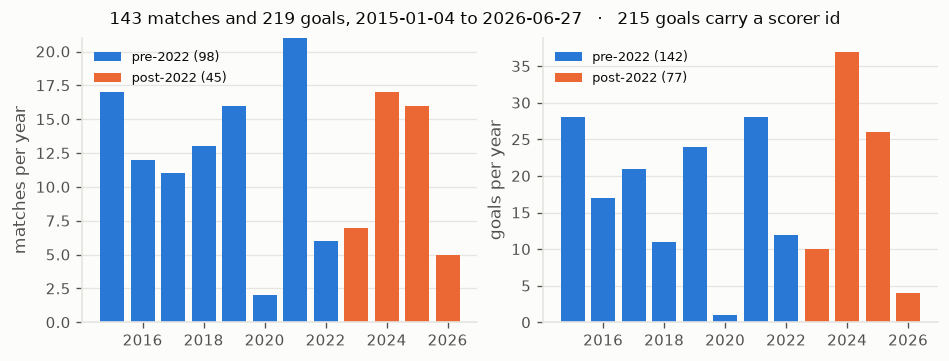

In [1]:
import sys, json
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "JordanData"))
import viz
viz.use_style()

SQUAD = ROOT / "outputs" / "squad"
START, CUT = pd.Timestamp("2015-01-01"), pd.Timestamp(viz.SPLIT)
rng = np.random.default_rng(41)

mt = pd.read_csv(SQUAD / "match_table.csv", parse_dates=["date"]).sort_values("date")
goals = pd.read_csv(SQUAD / "goals.csv", parse_dates=["date"])
ap = pd.read_csv(SQUAD / "appearances_combined.csv")
ja = ap[ap.squad_id == "3e22f0fa"].copy()
ja["Min"] = pd.to_numeric(ja.Min, errors="coerce")

mt = mt[mt.date >= START].copy()
goals = goals[goals.date >= START].copy()
for d in (mt, goals):
    d["era"] = np.where(d.date < CUT, "pre", "post")
mt["blk"] = mt.date.dt.year * 2 + (mt.date.dt.month > 6)

# A scorer is a player id, never a name -- the same man is transliterated
# several ways across sources (notebook 02, section 5).
gj = goals.dropna(subset=["scorer_player_id"]).copy()
NAMES = ja.dropna(subset=["player_id"]).groupby("player_id").Player.agg(
    lambda s: s.mode().iloc[0])

fig, axes = plt.subplots(1, 2, figsize=(7.8, 2.9))
yr = (mt.groupby([mt.date.dt.year, "era"]).size().unstack("era")
      .reindex(columns=["pre", "post"]).fillna(0))
gy = (goals.groupby([goals.date.dt.year, "era"]).size().unstack("era")
      .reindex(columns=["pre", "post"]).fillna(0))
for ax, tab, lab in ((axes[0], yr, "matches"), (axes[1], gy, "goals")):
    ax.bar(tab.index, tab["pre"], width=0.78, color=viz.BLUE,
           label=f"pre-2022 ({int(tab['pre'].sum())})")
    ax.bar(tab.index, tab["post"], bottom=tab["pre"], width=0.78, color=viz.ORANGE,
           label=f"post-2022 ({int(tab['post'].sum())})")
    ax.set_ylabel(f"{lab} per year")
    ax.legend(fontsize=8, loc="upper left")
    viz.despine(ax)
fig.suptitle(f"{len(mt)} matches and {len(goals)} goals, "
             f"{mt.date.min().date()} to {mt.date.max().date()}   ·   "
             f"{len(gj)} goals carry a scorer id", fontsize=10)
plt.show()

## 0. Is 2022 real?

A split date picked after seeing the results manufactures findings. This project
has already retired one effect on that ground — notebook 01's competitive-match
premium grew monotonically the later the cut was placed, which is what slicing a
trend looks like rather than what a change looks like.

So: slide the cut every six months from 2018 to 2024 and recompute. The axis
below is spaced by **matches** before the cut rather than by date, because that
is what actually moves the curve — on a date axis the 2020 shutdown stretches
into a flat run and fakes a break at mid-2021.

- a **change** ramps to the date, then **plateaus** — past the break, moving the
  cut only trades matches between two already-different groups
- a **trend** with no break **keeps climbing**

The cut moves; the data does not. This locates a date. It cannot explain one.

In [2]:
# One function per measure, each over an arbitrary set of matches, so the same
# code can be pointed at any candidate date. Sections 1 and 3 reuse them.
pos_by_match = {m: s.scorer_position.dropna().tolist() for m, s in goals.groupby("match_id")}
mins_by_match = {m: s.groupby("player_id").Min.sum() for m, s in ja.groupby("match_id")}
xi = mt.dropna(subset=["starting_xi"]).copy()
xi["ids"] = xi.starting_xi.map(lambda s: [p["id"] for p in json.loads(s) if p.get("id")])
XI = xi.set_index("match_id")

def mf_share(d):
    v = [p for m in d.match_id for p in pos_by_match.get(m, [])]
    return np.mean([x == "MF" for x in v]) if v else np.nan

def top11(d):
    tot = {}
    for m in d.match_id:
        s = mins_by_match.get(m)
        if s is None:
            continue
        for pid, v in s.items():
            tot[pid] = tot.get(pid, 0) + v
    if not tot:
        return np.nan
    p = pd.Series(tot).sort_values(ascending=False)
    return p.head(11).sum() / p.sum()

def top3_share(d):
    g = gj[gj.match_id.isin(set(d.match_id))].scorer_player_id
    if len(g) < 20:                    # too few goals to form a share
        return np.nan
    return g.value_counts(normalize=True).head(3).sum()

# Familiarity and appearance rate depend on the match and the FULL history
# behind it, never on which matches a bootstrap draw happens to pick -- so they
# are computed once per match here, and resampling only averages them.
# Both are divided by the matches available in the 24-month window, making them
# rates: raw counts accumulate with time and FBref's coverage starts in 2011, so
# the unadjusted versions rise for reasons that have nothing to do with Jordan.
fam_rate, caps_rate = {}, {}
for r in xi.itertuples():
    prior = xi[(xi.date >= r.date - pd.Timedelta(days=730)) & (xi.date < r.date)]
    if len(prior) < 15:                # too little history to form a rate
        continue
    pc, cc = {}, {}
    for q in prior.itertuples():
        for pair in combinations(sorted(q.ids), 2):
            pc[pair] = pc.get(pair, 0) + 1
        for i in q.ids:
            cc[i] = cc.get(i, 0) + 1
    pairs = list(combinations(sorted(r.ids), 2))
    fam_rate[r.match_id] = np.mean([pc.get(p, 0) for p in pairs]) / len(prior)
    caps_rate[r.match_id] = np.mean([cc.get(i, 0) for i in r.ids]) / len(prior)

def windowed(d, which):
    src = fam_rate if which == "fam" else caps_rate
    v = [src[m] for m in d.match_id if m in src]
    return np.mean(v) if v else np.nan

# coverage of these two rates is reported on the section 3 figure
XI_COVER = (len(fam_rate), len(xi))

In [3]:
SWEEP = [("minutes top-11", top11),
         ("familiarity", lambda d: windowed(d, "fam")),
         ("appearance rate", lambda d: windowed(d, "caps")),
         ("top-3 goal share", top3_share),
         ("midfielder share", mf_share)]

rows = []
for cut in pd.date_range("2018-07-01", "2024-07-01", freq="6MS"):
    pre, post = mt[mt.date < cut], mt[mt.date >= cut]
    if len(pre) < 25 or len(post) < 25:     # a side too thin to compare
        continue
    r = {"cut": cut.date(), "n_pre": len(pre), "n_post": len(post)}
    for lab, fn in SWEEP:
        x, y = fn(pre), fn(post)
        r[lab] = y - x if np.isfinite(x) and np.isfinite(y) else np.nan
    rows.append(r)
sweep = pd.DataFrame(rows)
# Two cut dates with no match between them describe the same split, so they are
# the same point -- keep one, labelled by the earlier date.
sweep = sweep.drop_duplicates(subset="n_pre", keep="first").reset_index(drop=True)

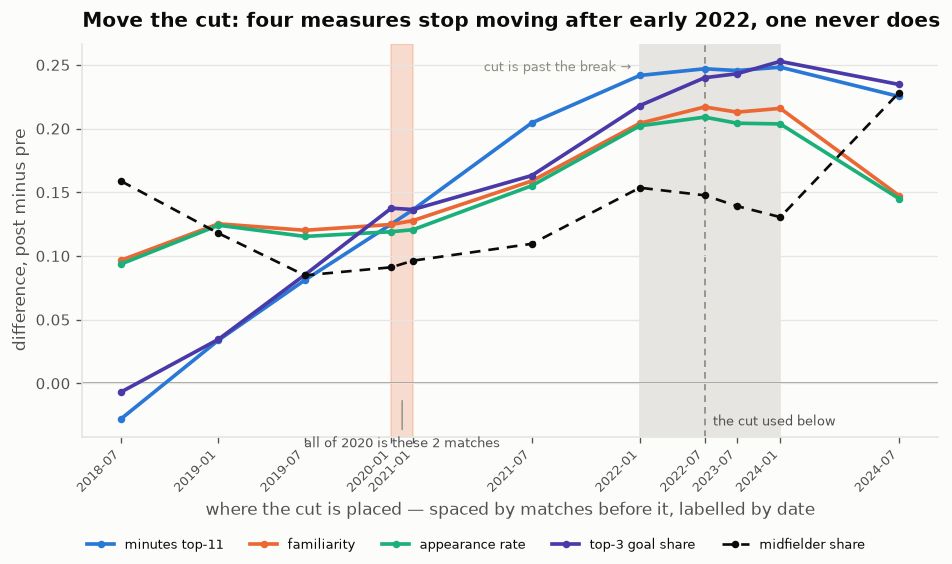

In [4]:
# Spaced by MATCHES before the cut, not by date. Nothing here moves with the
# calendar -- the curve only changes when matches cross the cut -- and Jordan
# played 2 matches in all of 2020, so a date axis stretches the shutdown into a
# flat stretch and makes the climb look like it begins in mid-2021.
fig, ax = plt.subplots(figsize=(7.8, 4.6))
x = sweep.n_pre.values
cut_x = int((mt.date < CUT).sum())
band = (int((mt.date < pd.Timestamp("2022-01-01")).sum()),
        int((mt.date < pd.Timestamp("2024-01-01")).sum()))

ax.axvspan(band[0], band[1], color=viz.GRID, zorder=0)
ax.annotate("cut is past the break →", xy=(band[0], 1.0),
            xycoords=("data", "axes fraction"), xytext=(-5, -10),
            textcoords="offset points", fontsize=8, color=viz.INK_MUTED,
            ha="right", va="top")
PALETTE = [viz.BLUE, viz.ORANGE, viz.AQUA, viz.VIOLET, viz.INK]
for (lab, _), col in zip(SWEEP, PALETTE):
    odd = lab == "midfielder share"          # the one that never settles
    ax.plot(x, sweep[lab], color=col, marker="o", ms=3.5, label=lab,
            lw=1.6 if odd else 2.2, ls=(0, (4, 3)) if odd else "-")
ax.axhline(0, color=viz.INK_MUTED, lw=0.9, zorder=0)
ax.axvline(cut_x, color=viz.INK_MUTED, lw=1.0, ls=(0, (4, 3)), zorder=0)
# down at the baseline, where the lines are not
ax.annotate("the cut used below", xy=(cut_x, 0.02), xycoords=("data", "axes fraction"),
            xytext=(5, 0), textcoords="offset points", fontsize=8,
            color=viz.INK_2, va="bottom")

ax.set_xticks(x)
ax.set_xticklabels([str(c)[:7] for c in sweep.cut], rotation=45, ha="right",
                   fontsize=8)
# The whole of 2020 spans this many matches. Shade it, so the compression is
# visible rather than asserted -- on a date axis it was a third of the chart.
y2020 = (int((mt.date < pd.Timestamp("2020-01-01")).sum()),
         int((mt.date < pd.Timestamp("2021-01-01")).sum()))
ax.axvspan(y2020[0], y2020[1], color=viz.ORANGE, alpha=0.22, zorder=0)
ax.annotate(f"all of 2020 is these {y2020[1] - y2020[0]} matches",
            xy=(sum(y2020) / 2, 0.10), xycoords=("data", "axes fraction"),
            xytext=(0, -30), textcoords="offset points", ha="center",
            fontsize=7.5, color=viz.INK_2,
            arrowprops=dict(arrowstyle="-", color=viz.INK_MUTED, lw=0.8))
ax.set_xlabel("where the cut is placed — spaced by matches before it, "
              "labelled by date")
ax.set_ylabel("difference, post minus pre")
ax.set_title("Move the cut: four measures stop moving after early 2022, one never does")
fig.legend(*ax.get_legend_handles_labels(), loc="outside lower center",
           ncol=5, fontsize=8)
viz.despine(ax)
ax.grid(axis="x", visible=False)
plt.show()

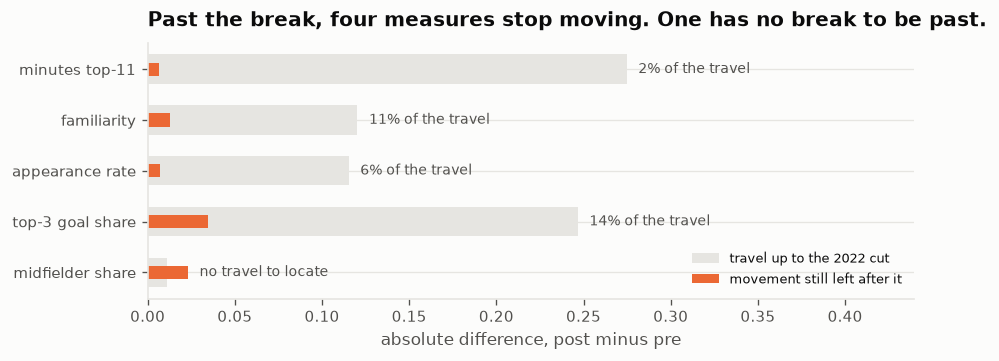

In [5]:
# Ramp  = how far a measure travels from the earliest cut to the one we use.
# Flat  = how much it still moves once the cut is PAST the break (shaded band).
# A real change has flat much smaller than ramp. A trend being sliced has the
# two comparable, because there is no break for the cut to get past.
band = pd.to_datetime(sweep.cut).between("2022-01-01", "2024-01-01")
chosen = sweep[pd.to_datetime(sweep.cut) == CUT].iloc[0]
shape = pd.DataFrame([{"measure": lab,
                       "ramp": abs(chosen[lab] - sweep[lab].iloc[0]),
                       "flat": sweep.loc[band, lab].max() - sweep.loc[band, lab].min()}
                      for lab, _ in SWEEP])
shape["located"] = shape.ramp >= 0.05

fig, ax = plt.subplots(figsize=(7.6, 2.9))
d = shape.iloc[::-1].reset_index(drop=True)
y = np.arange(len(d))
ax.barh(y, d.ramp, height=0.58, color=viz.GRID, label="travel up to the 2022 cut")
ax.barh(y, d.flat, height=0.26, color=viz.ORANGE,
        label="movement still left after it")
for i, r in d.iterrows():
    txt = f"{r.flat / r.ramp:.0%} of the travel" if r.located else "no travel to locate"
    ax.annotate(txt, (max(r.ramp, r.flat), i), xytext=(7, 0), va="center",
                textcoords="offset points", fontsize=8.5, color=viz.INK_2)
ax.set_yticks(y)
ax.set_yticklabels(d.measure)
ax.set_xlim(0, d.ramp.max() * 1.6)
ax.set_xlabel("absolute difference, post minus pre")
ax.set_title("Past the break, four measures stop moving. One has no break to be past.")
ax.legend(fontsize=8, loc="lower right")
viz.despine(ax)
plt.show()

**Four of five behave like a real change.** Minutes concentration, familiarity,
appearance rate and top-3 goal share climb from 2018, arrive by **2022-01**, then
sit still — two further years of cut move minutes top-11 by 0.007 on a rise of
0.275.

🚨 **The fifth does not.** Midfielder share of goals is as large at a 2018 cut as
at 2022, sags between, and peaks at the final cut where only 27 matches remain
post. The sweep cannot locate a date for it. Its interval in section 3 still
excludes zero — the post-2022 team does score more from midfield — but that is a
fact about two groups, not about mid-2022. **The weakest of the four.**

The claim the sweep supports is **"no later than early 2022"**, not July
specifically: the plateau is already reached at the 2022-01 cut, a handful of
fixtures away. Nothing below depends on the difference.

## 1. The goals came from fewer players

"How many different men scored" is a **species-richness** problem, and richness
rises with sample size whatever the true diversity. The post era has far fewer
goals, so raw counts are not comparable.

The fix is **rarefaction** (Gotelli & Colwell 2001; Hurlbert 1971): draw the
larger era down to the smaller era's size, repeatedly, and compare distributions
rather than points.

In [6]:
pre_s = gj[gj.era == "pre"].scorer_player_id
post_s = gj[gj.era == "post"].scorer_player_id
n_post = len(post_s)

def profile(s):
    vc = s.value_counts(); p = vc / vc.sum()
    return np.array([len(vc), p.iloc[0], p.head(3).sum(), (p ** 2).sum()])

obs = profile(post_s)
draws = np.array([profile(pre_s.sample(n_post, replace=False,
                                       random_state=int(rng.integers(1e9))))
                  for _ in range(4000)])

LABELS = ["distinct scorers", "top-1 share", "top-3 share", "HHI"]
rows = []
for i, lab in enumerate(LABELS):
    lo, hi = np.percentile(draws[:, i], [2.5, 97.5])
    rows.append({"measure": lab, "post": obs[i], "pre_lo": lo, "pre_hi": hi,
                 "verdict": "outside" if not (lo <= obs[i] <= hi) else "inside"})
rar = pd.DataFrame(rows)   # drawn by the next two cells
RAR_N = (n_post, int(obs[0]), len(pre_s), pre_s.nunique())

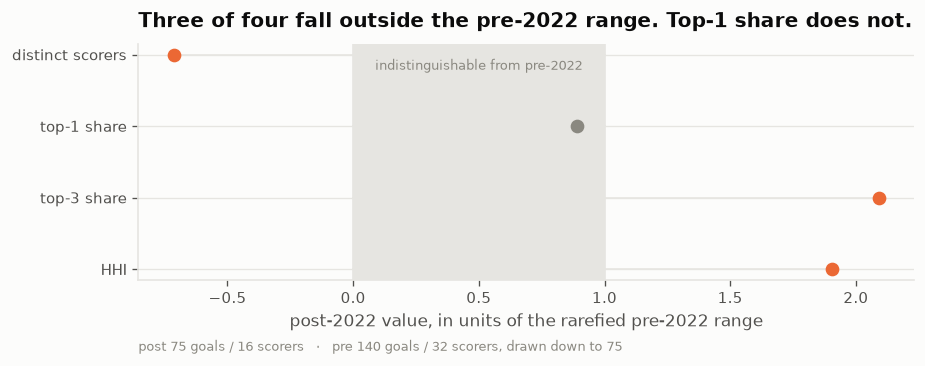

In [7]:
# Four measures, four different units. Put them on one axis by expressing the
# post-2022 value in units of its OWN rarefied pre-2022 range: 0 is that range's
# floor, 1 its ceiling. Inside the band means indistinguishable from a pre-2022
# sample of the same size.
fig, ax = plt.subplots(figsize=(7.6, 2.9))
d = rar.iloc[::-1].reset_index(drop=True)
z = (d.post - d.pre_lo) / (d.pre_hi - d.pre_lo)
ax.axvspan(0, 1, color=viz.GRID, zorder=0)
ax.annotate("indistinguishable from pre-2022", xy=(0.5, 1.0),
            xycoords=("data", "axes fraction"), xytext=(0, -9),
            textcoords="offset points", ha="center", va="top", fontsize=8,
            color=viz.INK_MUTED)
for i, (v, verdict) in enumerate(zip(z, d.verdict)):
    col = viz.ORANGE if verdict == "outside" else viz.INK_MUTED
    ax.plot([min(v, 0), max(v, 1)], [i, i], color=viz.GRID, lw=1.0, zorder=1)
    ax.scatter([v], [i], color=col, s=52, zorder=3)
ax.set_yticks(range(len(d)))
ax.set_yticklabels(d.measure)
ax.set_xlabel("post-2022 value, in units of the rarefied pre-2022 range")
ax.set_title("Three of four fall outside the pre-2022 range. Top-1 share does not.")
ax.annotate(f"post {RAR_N[0]} goals / {RAR_N[1]} scorers   ·   "
            f"pre {RAR_N[2]} goals / {RAR_N[3]} scorers, drawn down to {RAR_N[0]}",
            xy=(0, -0.30), xycoords="axes fraction", fontsize=8, color=viz.INK_MUTED)
viz.despine(ax)
plt.show()

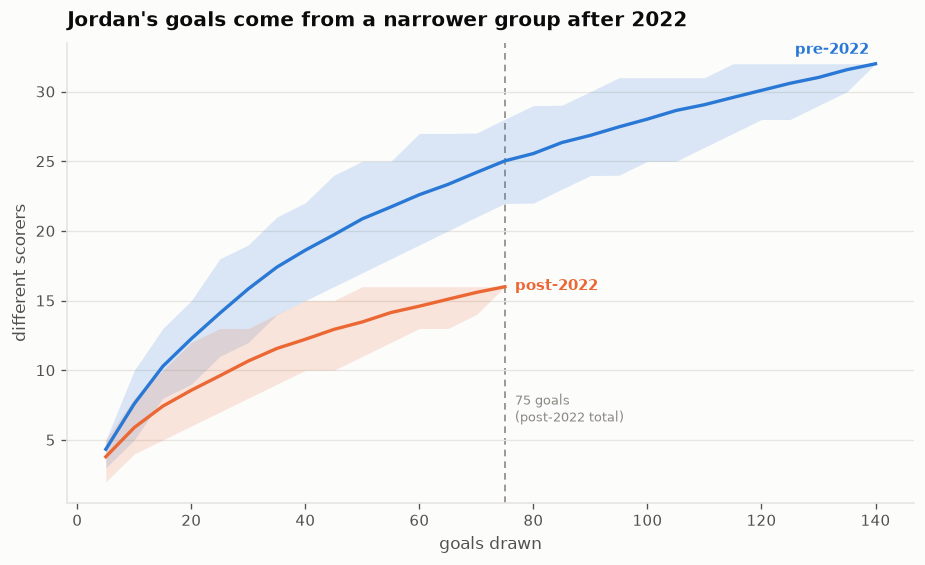

In [8]:
# Rarefaction curve: how many scorers a sample of k goals yields, pre vs post.
def curve(s, ks, reps=400):
    out = []
    for k in ks:
        if k > len(s):
            out.append((np.nan, np.nan, np.nan)); continue
        v = [s.sample(k, replace=False,
                      random_state=int(rng.integers(1e9))).nunique()
             for _ in range(reps)]
        out.append((np.mean(v), *np.percentile(v, [2.5, 97.5])))
    return np.array(out)

ks = np.arange(5, len(pre_s) + 1, 5)
c_pre = curve(pre_s, ks)
ks_post = np.arange(5, n_post + 1, 5)
c_post = curve(post_s, ks_post)

fig, ax = plt.subplots(figsize=(7.6, 4.6))
ax.fill_between(ks, c_pre[:, 1], c_pre[:, 2], color=viz.BLUE, alpha=0.16, lw=0)
ax.plot(ks, c_pre[:, 0], color=viz.BLUE, label="pre-2022")
ax.fill_between(ks_post, c_post[:, 1], c_post[:, 2], color=viz.ORANGE, alpha=0.16, lw=0)
ax.plot(ks_post, c_post[:, 0], color=viz.ORANGE, label="post-2022")
ax.axvline(n_post, color=viz.INK_MUTED, lw=1.0, ls=(0, (4, 3)), zorder=0)
ax.annotate(f"{n_post} goals\n(post-2022 total)", xy=(n_post, 6),
            xytext=(6, 0), textcoords="offset points",
            fontsize=8, color=viz.INK_MUTED, va="bottom")
ax.annotate("pre-2022", xy=(ks[-1], c_pre[-1, 0]), xytext=(-4, 6),
            textcoords="offset points", color=viz.BLUE, fontsize=9,
            ha="right", fontweight="bold")
ax.annotate("post-2022", xy=(ks_post[-1], c_post[-1, 0]), xytext=(6, -2),
            textcoords="offset points", color=viz.ORANGE, fontsize=9,
            fontweight="bold")
ax.set_xlabel("goals drawn"); ax.set_ylabel("different scorers")
ax.set_title("Jordan's goals come from a narrower group after 2022")
viz.despine(ax)
plt.show()

**At any common number of goals, the post-2022 era uses fewer scorers** — the
curves separate well before the cut, so this is not an artefact of era length.

🚨 **But it is not one man.** Top-1 share sits *inside* the rarefied range:
Jordan's leading scorer takes no more of the load than a same-sized pre-2022
sample would. Breadth moves; the individual does not. A narrowing onto a small
**group** — and "one player carries them" is not supportable.

## 2. Who

Half a changing of the guard. Two high-volume pre-2022 scorers vanish; the three
who take over were **already there**, scoring before 2022 and then scaling up.

In [9]:
tab = (gj.pivot_table(index="scorer_player_id", columns="era",
                      values="match_id", aggfunc="size")
       .reindex(columns=["pre", "post"]).fillna(0).astype(int))
tab["total"] = tab.sum(axis=1)
tab.insert(0, "player", tab.index.map(NAMES))
top = tab.sort_values("total", ascending=False).head(10)
# the table and the top-three shares are both drawn by the next cell

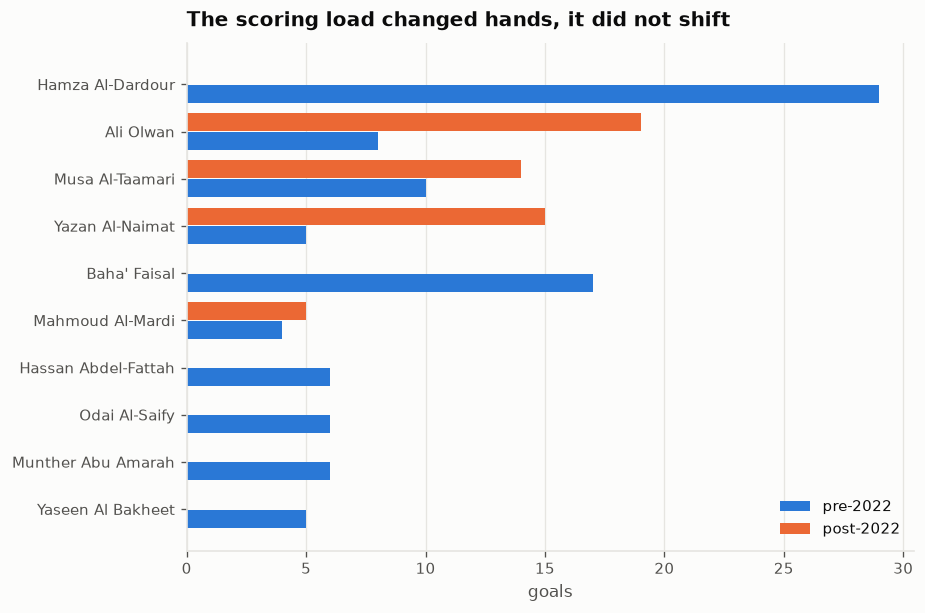

In [10]:
fig, ax = plt.subplots(figsize=(7.6, 5.0))
d = top.iloc[::-1]
y = np.arange(len(d))
ax.barh(y - 0.2, d.pre, height=0.38, color=viz.BLUE, label="pre-2022")
ax.barh(y + 0.2, d.post, height=0.38, color=viz.ORANGE, label="post-2022")
ax.set_yticks(y); ax.set_yticklabels(d.player)
ax.set_xlabel("goals")
ax.set_title("The scoring load changed hands, it did not shift")
ax.legend(loc="lower right")
viz.despine(ax)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
plt.show()

**The old top two disappear** — not reduced roles, zero goals.

**The new top three were already scoring**, then roughly double or triple.
Al-Taamari is in the top three of *both* eras, so "Jordan replaced its forwards"
would be an overstatement.

Section 1's narrowing is not a squad rebuilt. It is a wide, flat distribution
collapsing onto three players already in it. Whether that is finding your best
attackers or running out of alternatives, this data cannot say.

## 3. A narrower group, a more settled team

If the goals narrowed, did the *team*? Three measures, each built to survive the
same confound: raw counts accumulate with time, and FBref's coverage starts in
2011, so the naive versions rise for reasons unrelated to Jordan.

- **Minutes concentration** — share of minutes to the top eleven, at equal match
  counts.
- **Team familiarity** — pairwise prior appearances together (*Journal of Big
  Data*, 2025), restricted to a **24-month lookback** and divided by the matches
  available in it, making it a rate that cannot drift.
- **Appearance rate** — the same treatment for individual starters.

Plus **midfield share of goals**, which needs no correction.

In [11]:
BLOCKS = {e: [d for _, d in mt[mt.era == e].groupby("blk")] for e in ("pre", "post")}

def block_boot(fn, nb=600):
    """Resample six-month blocks within each era; matches in a window are not
    independent draws, so the block is the unit (Kunsch 1989)."""
    obs = fn(mt[mt.era == "post"]) - fn(mt[mt.era == "pre"])
    vals = []
    for _ in range(nb):
        s = {e: pd.concat([BLOCKS[e][i]
                           for i in rng.integers(0, len(BLOCKS[e]), len(BLOCKS[e]))])
             for e in ("pre", "post")}
        v = fn(s["post"]) - fn(s["pre"])
        if np.isfinite(v):
            vals.append(v)
    lo, hi = np.percentile(vals, [2.5, 97.5])
    return obs, lo, hi

MEASURES = [
    ("midfielder share of goals", mf_share, 600),
    ("minutes: top-11 share", top11, 600),
    ("familiarity rate (pairs)", lambda d: windowed(d, "fam"), 600),
    ("appearance rate (starters)", lambda d: windowed(d, "caps"), 600),
]
res = []
for lab, fn, nb in MEASURES:
    o, lo, hi = block_boot(fn, nb)
    res.append({"measure": lab, "pre": fn(mt[mt.era == "pre"]),
                "post": fn(mt[mt.era == "post"]),
                "diff": o, "lo": lo, "hi": hi,
                "excludes_0": bool(lo > 0 or hi < 0)})
settled = pd.DataFrame(res)   # drawn by the next cell

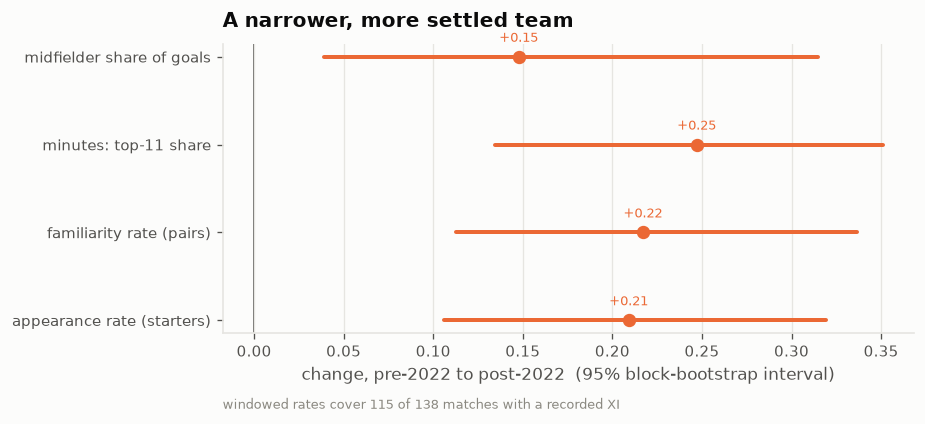

In [12]:
fig, ax = plt.subplots(figsize=(7.6, 3.4))
d = settled.iloc[::-1].reset_index(drop=True)
y = np.arange(len(d))
for i, r in d.iterrows():
    col = viz.ORANGE if r.excludes_0 else viz.INK_MUTED
    ax.plot([r.lo, r.hi], [i, i], color=col, lw=2.4, solid_capstyle="round")
    ax.plot(r["diff"], i, "o", color=col, ms=7, zorder=3)
    ax.annotate(f"{r['diff']:+.2f}", xy=(r["diff"], i), xytext=(0, 9),
                textcoords="offset points", ha="center", fontsize=8, color=col)
ax.axvline(0, color=viz.INK_2, lw=1.0, zorder=0)
ax.set_yticks(y); ax.set_yticklabels(d.measure)
ax.set_xlabel("change, pre-2022 to post-2022  (95% block-bootstrap interval)")
ax.set_title("A narrower, more settled team")
ax.annotate(f"windowed rates cover {XI_COVER[0]} of {XI_COVER[1]} matches with a "
            f"recorded XI", xy=(0, -0.26), xycoords="axes fraction", fontsize=8,
            color=viz.INK_MUTED)
viz.despine(ax)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
plt.show()

All four clear zero: more minutes to fewer players, players who have played
together more recently, more goals from midfield.

Keep the last one separate. The others describe **stability**; midfield share
describes **shape** — consistent evidence, not the same evidence. And per section
0, it is the one measure that cannot locate a date.

## 4. When the goals happen

Not who scored but when, and what the scoreboard said. Reconstructed in
`JordanData/match_state.py` from goal minutes on **both** sides, including the
ten Arab Cup matches recovered from Wikipedia that FBref does not carry.

Coverage is 155 of 174 matches; the cell prints the count inside this window. The
gap is FBref reports with no event feed, and it is **balanced across eras** —
which it was not before the Arab Cup was recovered, when the missing matches were
disproportionately Jordan's best.

In [13]:
ms = pd.read_csv(SQUAD / "match_state.csv", parse_dates=["date"])
ms = ms[(ms.date >= START) & ms.jordan_side.notna()].copy()
ms["era"] = np.where(ms.date < CUT, "pre", "post")
BUCK = ["1-15", "16-30", "31-45", "46-60", "61-75", "76-90"]
f_tot = ms[[f"for_{b}" for b in BUCK]].sum().values
a_tot = ms[[f"against_{b}" for b in BUCK]].sum().values
prof = pd.DataFrame({"window": BUCK,
                     "scored": f_tot / f_tot.sum(),
                     "conceded": a_tot / a_tot.sum()})
MS_N = (len(ms), int(f_tot.sum()), int(a_tot.sum()))   # drawn by the next cell

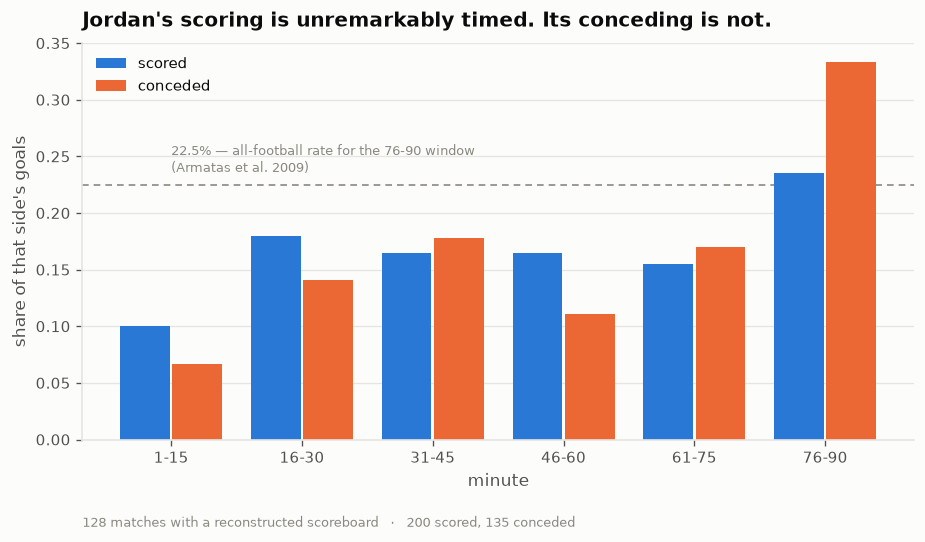

In [14]:
fig, ax = plt.subplots(figsize=(7.6, 4.4))
x = np.arange(len(BUCK))
ax.bar(x - 0.2, prof.scored, width=0.38, color=viz.BLUE, label="scored")
ax.bar(x + 0.2, prof.conceded, width=0.38, color=viz.ORANGE, label="conceded")
ax.axhline(0.225, color=viz.INK_MUTED, lw=1.0, ls=(0, (4, 3)), zorder=0)
ax.annotate("22.5% — all-football rate for the 76-90 window\n(Armatas et al. 2009)",
            xy=(0, 0.225), xytext=(0, 5), textcoords="offset points",
            fontsize=8, color=viz.INK_MUTED, va="bottom")
ax.set_xticks(x); ax.set_xticklabels(BUCK)
ax.set_xlabel("minute"); ax.set_ylabel("share of that side's goals")
ax.set_title("Jordan's scoring is unremarkably timed. Its conceding is not.")
ax.annotate(f"{MS_N[0]} matches with a reconstructed scoreboard   ·   "
            f"{MS_N[1]} scored, {MS_N[2]} conceded",
            xy=(0, -0.22), xycoords="axes fraction", fontsize=8, color=viz.INK_MUTED)
ax.legend(loc="upper left")
viz.despine(ax)
ax.grid(axis="x", visible=False); ax.grid(axis="y", visible=True)
plt.show()

Jordan's scoring sits on the all-football benchmark — the attack has no special
relationship with the clock. **The conceding column is the outlier: a third of
every goal Jordan concedes arrives in the last fifteen minutes**, about half
again what Armatas et al. (2009) expect.

This describes all 155 matches, **not** a change across 2022 — the era difference
there does not clear zero. A standing feature, and the clearest thing in the
notebook pointing at something to fix.

## 5. Crossing the two: when *and* in what state

"A third of goals conceded arrive after the 75th" fits two opposite stories: a
team that throws away leads, or one that gets put away in matches it was already
losing. Neither section settles it alone.

Crossing them does. Rates need **minutes at risk** per cell, not goal counts — a
team that spends the last fifteen minutes level has more chance to concede a
level-state goal simply by being there.

In [15]:
cells = pd.read_csv(SQUAD / "state_time_cells.csv")
cells = cells[cells.match_id.isin(set(mt.match_id))]          # 2015+ window
grid = (cells.groupby(["window", "state"])
        .agg(minutes=("minutes", "sum"), ga=("ga", "sum"), gf=("gf", "sum"))
        .reset_index())
grid["conceded_per90"] = grid.ga / grid.minutes * 90
grid["scored_per90"] = grid.gf / grid.minutes * 90
ORDER = ["1-15", "16-30", "31-45", "46-60", "61-75", "76-90"]

# rates and the minutes behind them are both drawn by the next cell

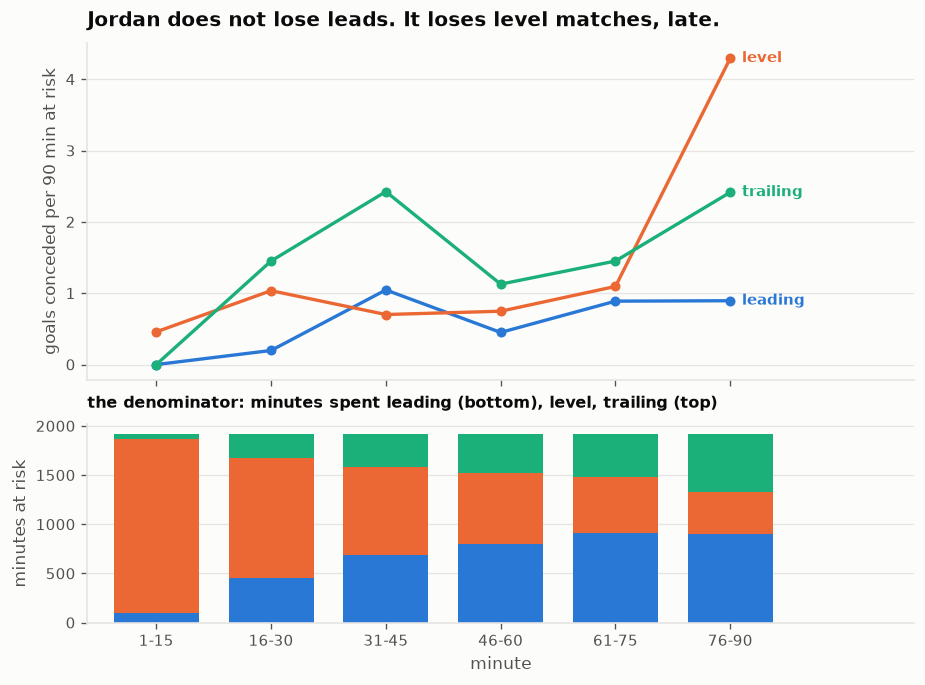

In [16]:
# A rate is a fraction, so both halves get drawn: the rate, and the minutes
# at risk underneath it. The late level cell is the smallest denominator on the
# chart, which is why its interval is wide.
fig, axes = plt.subplots(2, 1, figsize=(7.6, 5.6), sharex=True,
                         gridspec_kw={"height_ratios": [1.7, 1]})
x = np.arange(len(ORDER))
STATES = (("leading", viz.BLUE), ("level", viz.ORANGE), ("trailing", viz.AQUA))
a = axes[0]
for st, col in STATES:
    y = grid[grid.state == st].set_index("window").reindex(ORDER).conceded_per90
    a.plot(x, y.values, color=col, marker="o", label=st)
    a.annotate(st, xy=(x[-1], y.values[-1]), xytext=(7, 0),
               textcoords="offset points", color=col, fontsize=9,
               va="center", fontweight="bold")
a.set_ylabel("goals conceded per 90 min at risk")
a.set_title("Jordan does not lose leads. It loses level matches, late.")
viz.despine(a)

b = axes[1]
bot = np.zeros(len(ORDER))
for st, col in STATES:
    m = grid[grid.state == st].set_index("window").reindex(ORDER).minutes.fillna(0).values
    b.bar(x, m, bottom=bot, width=0.74, color=col, label=st)
    bot = bot + m
b.set_xticks(x)
b.set_xticklabels(ORDER)
b.set_xlim(-0.6, len(ORDER) + 0.6)
b.set_xlabel("minute")
b.set_ylabel("minutes at risk")
b.set_title("the denominator: minutes spent leading (bottom), level, trailing (top)",
            fontsize=9.5)
viz.despine(b)
plt.show()

The blue line is the control and it is flat: **with a lead, Jordan's conceding
rate in the last fifteen minutes is indistinguishable from the fifteen before
it.** Leads are not the problem.

The orange line is the finding. While **level**, the conceding rate roughly
quadruples going into the final window.

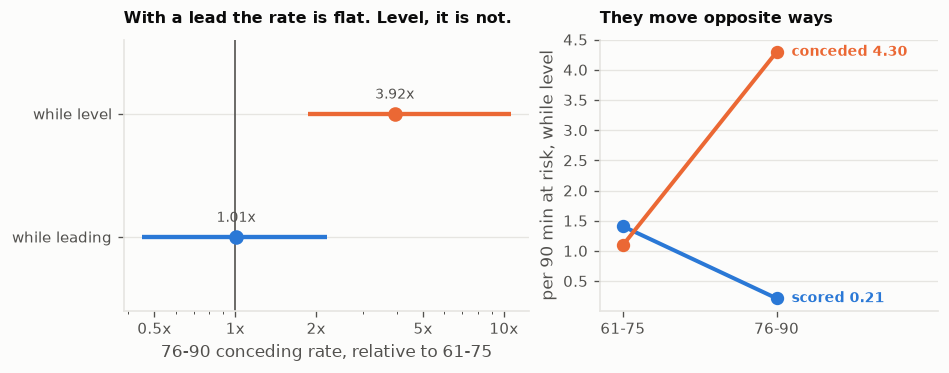

In [17]:
# The contrast, bootstrapped over matches in six-month blocks.
by_match = {m: d for m, d in cells.groupby("match_id")}
blocks = [d.match_id.tolist() for _, d in mt.groupby("blk")]

def rate(ms_, window, state, direction="ga"):
    d = pd.concat([by_match[m] for m in ms_ if m in by_match])
    s = d[(d.window == window) & (d.state == state)]
    return s[direction].sum() / s.minutes.sum() * 90 if s.minutes.sum() > 0 else np.nan

def ratio(ms_, state):
    late, before = rate(ms_, "76-90", state), rate(ms_, "61-75", state)
    return late / before if before and np.isfinite(before) else np.nan

allm = mt.match_id.tolist()
ratios = []
for st in ("leading", "level"):
    obs = ratio(allm, st)
    draws = []
    for _ in range(1500):
        pick = [m for i in rng.integers(0, len(blocks), len(blocks)) for m in blocks[i]]
        v = ratio(pick, st)
        if np.isfinite(v):
            draws.append(v)
    lo, hi = np.percentile(draws, [2.5, 97.5])
    ratios.append({"state": st, "obs": obs, "lo": lo, "hi": hi})
ratios = pd.DataFrame(ratios)

fig, axes = plt.subplots(1, 2, figsize=(7.8, 3.0),
                         gridspec_kw={"width_ratios": [1.2, 1]})
a = axes[0]
for i, r in ratios.iterrows():
    col = viz.ORANGE if r.lo > 1 else viz.BLUE
    a.hlines(i, r.lo, r.hi, color=col, lw=2.6)
    a.scatter([r.obs], [i], color=col, s=60, zorder=3)
    a.annotate(f"{r.obs:.2f}x", (r.obs, i), xytext=(0, 9), ha="center",
               textcoords="offset points", fontsize=8.5, color=viz.INK_2)
a.axvline(1.0, color=viz.INK_2, lw=1.0)
a.set_xscale("log")
a.set_xticks([0.5, 1, 2, 5, 10])
a.set_xticklabels(["0.5x", "1x", "2x", "5x", "10x"])
a.set_yticks(range(len(ratios)))
a.set_yticklabels([f"while {v}" for v in ratios.state])
a.set_ylim(-0.6, len(ratios) - 0.4)
a.set_xlabel("76-90 conceding rate, relative to 61-75")
a.set_title("With a lead the rate is flat. Level, it is not.", fontsize=9.5)
viz.despine(a)

# The internal control: if level matches were simply frantic, BOTH rates rise.
b = axes[1]
for lab, direction, col in (("scored", "gf", viz.BLUE), ("conceded", "ga", viz.ORANGE)):
    v = [rate(allm, w, "level", direction) for w in ("61-75", "76-90")]
    b.plot([0, 1], v, color=col, lw=2.4, marker="o", ms=7, label=lab)
    b.annotate(f"{lab} {v[1]:.2f}", (1, v[1]), xytext=(9, 0), va="center",
               textcoords="offset points", fontsize=8.5, color=col,
               fontweight="bold")
b.set_xticks([0, 1])
b.set_xticklabels(["61-75", "76-90"])
b.set_xlim(-0.15, 2.05)
b.set_ylabel("per 90 min at risk, while level")
b.set_title("They move opposite ways", fontsize=9.5)
viz.despine(b)
b.grid(axis="x", visible=False)
plt.show()

So it is not that level matches get frantic and goals fly both ways. Jordan's
*scoring* rate while level collapses in the same window its conceding rate
quadruples. The asymmetry is the point.

Two checks before trusting it.

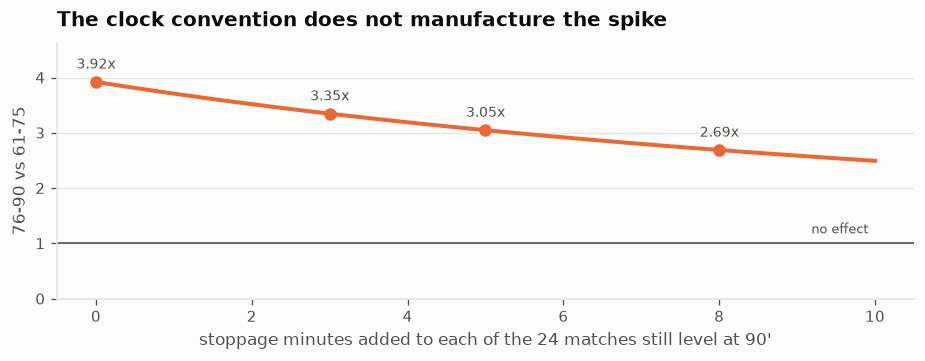

In [18]:
# The goal timelines, the same ones match_state builds its own table from.
from match_state import goal_timelines
TL = {m: v for m, v in goal_timelines().items() if m in set(mt.match_id)}
info = mt.set_index("match_id")

# Check 1 -- stoppage time. Minutes at risk stop at 90 for every match, but
# stoppage is always played, so the last window's rate is inflated for
# everyone. Adding it back can only shrink the effect. How much does it take?
level_at_90 = sum(1 for tl, _s, _x in TL.values()
                  if sum(d for m, d in tl if m <= 90) == 0)
lvl = grid[grid.state == "level"].set_index("window")
extra = np.linspace(0, 10, 101)
mins = lvl.loc["76-90", "minutes"] + extra * level_at_90
curve = (lvl.loc["76-90", "ga"] / mins * 90) / lvl.loc["61-75", "conceded_per90"]

fig, ax = plt.subplots(figsize=(7.6, 2.9))
ax.plot(extra, curve, color=viz.ORANGE, lw=2.4)
ax.axhline(1.0, color=viz.INK_2, lw=1.0)
ax.annotate("no effect", xy=(10, 1.0), xytext=(-4, 6), ha="right",
            textcoords="offset points", fontsize=8, color=viz.INK_2)
for e in (0, 3, 5, 8):
    v = (lvl.loc["76-90", "ga"] / (lvl.loc["76-90", "minutes"] + e * level_at_90)
         * 90) / lvl.loc["61-75", "conceded_per90"]
    ax.scatter([e], [v], color=viz.ORANGE, s=42, zorder=3)
    ax.annotate(f"{v:.2f}x", (e, v), xytext=(0, 8), ha="center",
                textcoords="offset points", fontsize=8.5, color=viz.INK_2)
ax.set_ylim(0, max(curve) * 1.18)
ax.set_xlabel(f"stoppage minutes added to each of the {level_at_90} matches still level at 90'")
ax.set_ylabel("76-90 vs 61-75")
ax.set_title("The clock convention does not manufacture the spike")
viz.despine(ax)
ax.grid(axis="x", visible=False)
plt.show()

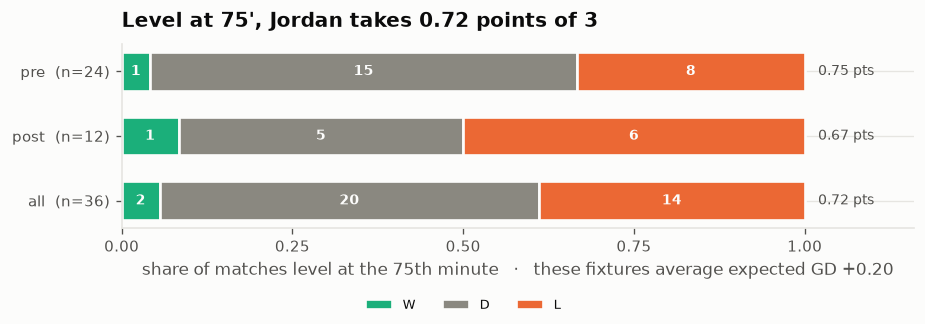

In [19]:
# Check 2 -- outcomes, independent of the rate arithmetic entirely.
rows = []
for mid, (tl, _s, _x) in TL.items():
    if sum(d for m, d in tl if m <= 75) != 0:      # level at 75' only
        continue
    dft = sum(d for _, d in tl)
    r = info.loc[mid]
    rows.append({"match_id": mid, "date": r.date, "era": r.era,
                 "opponent": r.opponent, "expected_gf": r.expected_gf,
                 "expected_ga": r.expected_ga, "expected_gd": r.expected_gd,
                 "pts": 3 if dft > 0 else (1 if dft == 0 else 0),
                 "result": "W" if dft > 0 else ("D" if dft == 0 else "L")})
L = pd.DataFrame(rows)
wdl = (pd.crosstab(L.era, L.result).reindex(columns=["W", "D", "L"]).fillna(0)
       .astype(int).reindex(["pre", "post"]))
wdl.loc["all"] = wdl.sum()

fig, ax = plt.subplots(figsize=(7.6, 2.6))
y = np.arange(len(wdl))[::-1]
left = np.zeros(len(wdl))
for res, col in (("W", viz.AQUA), ("D", viz.INK_MUTED), ("L", viz.ORANGE)):
    v = wdl[res].values / wdl.sum(axis=1).values
    ax.barh(y, v, left=left, height=0.6, color=col, label=res,
            edgecolor=viz.SURFACE, linewidth=1.6)
    for yy, (frac, n, l0) in enumerate(zip(v, wdl[res].values, left)):
        if n:
            ax.annotate(str(n), (l0 + frac / 2, y[yy]), ha="center", va="center",
                        fontsize=8.5, color=viz.SURFACE, fontweight="bold")
    left = left + v
for i, e in enumerate(wdl.index):
    d = L if e == "all" else L[L.era == e]
    ax.annotate(f"{d.pts.mean():.2f} pts", (1.0, y[i]), xytext=(8, 0), va="center",
                textcoords="offset points", fontsize=8.5, color=viz.INK_2)
ax.set_yticks(y)
ax.set_yticklabels([f"{e}  (n={int(n)})" for e, n in zip(wdl.index, wdl.sum(axis=1))])
ax.set_xlim(0, 1.16)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
ax.set_xlabel(f"share of matches level at the 75th minute   ·   these fixtures "
              f"average expected GD {L.expected_gd.mean():+.2f}")
ax.set_title(f"Level at 75', Jordan takes {L.pts.mean():.2f} points of 3")
fig.legend(*ax.get_legend_handles_labels(), loc="outside lower center", ncol=3,
           fontsize=8)
viz.despine(ax)
ax.grid(axis="x", visible=False)
plt.show()

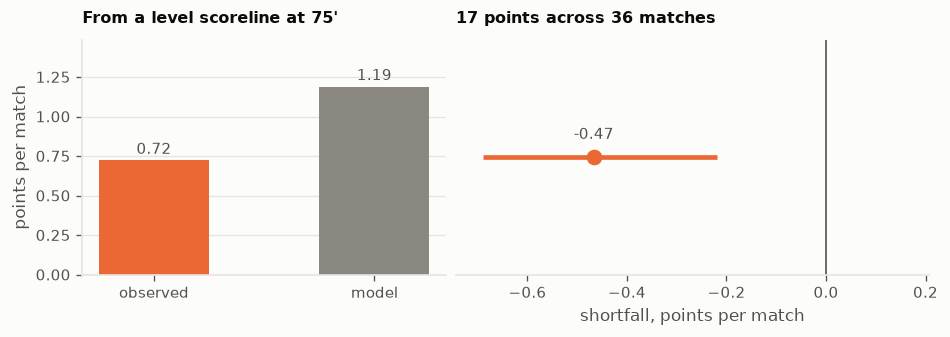

In [20]:
# Opponent-adjusted: what should a level scoreline at 75' be worth against
# THESE opponents? Simulate the remaining 15 minutes at each fixture's own
# model goal rates, which is the same adjustment gd_above_expected applies to
# a full match.
sim = []
for r in L.itertuples():
    kf = rng.poisson(r.expected_gf * 15 / 90, 40000)
    ka = rng.poisson(r.expected_ga * 15 / 90, 40000)
    d = kf - ka
    sim.append(np.where(d > 0, 3, np.where(d == 0, 1, 0)).mean())
sim = np.array(sim)
obs, exp = L.pts.mean(), sim.mean()
draws = [(L.pts.values[p].mean() - sim[p].mean())
         for p in (rng.integers(0, len(L), len(L)) for _ in range(5000))]
lo, hi = np.percentile(draws, [2.5, 97.5])

fig, axes = plt.subplots(1, 2, figsize=(7.8, 2.7),
                         gridspec_kw={"width_ratios": [1, 1.3]})
a = axes[0]
a.bar([0, 1], [obs, exp], width=0.5, color=[viz.ORANGE, viz.INK_MUTED])
for i, v in enumerate((obs, exp)):
    a.annotate(f"{v:.2f}", (i, v), xytext=(0, 4), ha="center",
               textcoords="offset points", fontsize=9, color=viz.INK_2)
a.set_xticks([0, 1])
a.set_xticklabels(["observed", "model"])
a.set_ylim(0, max(obs, exp) * 1.25)
a.set_ylabel("points per match")
a.set_title("From a level scoreline at 75'", fontsize=9.5)
viz.despine(a)

b = axes[1]
b.hlines(0, lo, hi, color=viz.ORANGE, lw=2.8)
b.scatter([obs - exp], [0], color=viz.ORANGE, s=70, zorder=3)
b.axvline(0, color=viz.INK_2, lw=1.0)
b.annotate(f"{obs - exp:+.2f}", (obs - exp, 0), xytext=(0, 11), ha="center",
           textcoords="offset points", fontsize=9, color=viz.INK_2)
b.set_ylim(-1, 1)
b.set_yticks([])
b.set_xlim(min(lo, 0) * 1.08, max(abs(lo), 0.05) * 0.30)
b.set_xlabel("shortfall, points per match")
b.set_title(f"{abs(obs - exp) * len(L):.0f} points across {len(L)} matches",
            fontsize=9.5)
viz.despine(b, keep=("bottom",))
plt.show()

A level scoreline at 75 minutes against these opponents should be worth ~1.2
points. Jordan takes **0.72** — roughly half a point per match short, interval
excluding zero, across 36 matches.

Not the clock convention: adding eight minutes of stoppage to every one of them
still leaves the spike at ~2.7×. Not opponent quality: the adjustment handles
that, and these are fixtures Jordan was favoured in.

🚨 **Partly the model, though.** The simulation setting that 1.2 draws goals at a
constant rate whatever the scoreboard says. How much that costs is measured in
**What we can still improve**; read the number with that attached.

### Did this change between the eras?

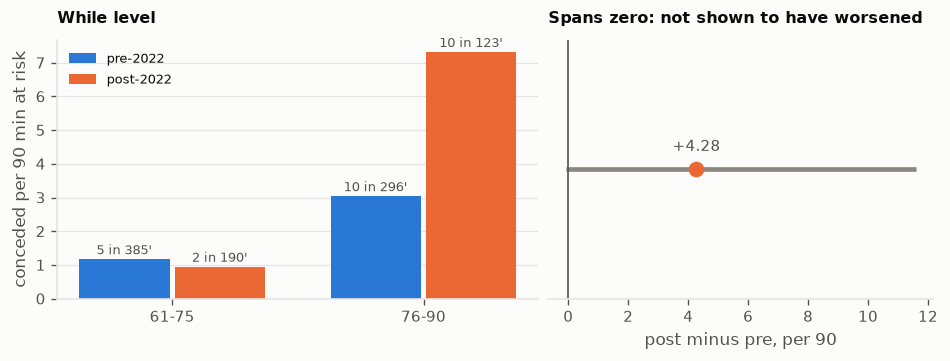

In [21]:
cells["era"] = cells.match_id.map(mt.set_index("match_id").era)
cellsum = []
for e in ("pre", "post"):
    d = cells[(cells.era == e) & (cells.state == "level")]
    for w in ("61-75", "76-90"):
        q = d[d.window == w]
        cellsum.append({"era": e, "window": w, "ga": int(q.ga.sum()),
                        "minutes": q.minutes.sum(),
                        "per90": q.ga.sum() / q.minutes.sum() * 90})
cellsum = pd.DataFrame(cellsum)

def late_level(ms_):
    return rate(ms_, "76-90", "level")

pre_m = mt[mt.era == "pre"].match_id.tolist()
post_m = mt[mt.era == "post"].match_id.tolist()
blk = {e: [d.match_id.tolist() for _, d in mt[mt.era == e].groupby("blk")]
       for e in ("pre", "post")}
draws = []
for _ in range(2000):
    s = {e: [m for i in rng.integers(0, len(blk[e]), len(blk[e])) for m in blk[e][i]]
         for e in ("pre", "post")}
    v = late_level(s["post"]) - late_level(s["pre"])
    if np.isfinite(v):
        draws.append(v)
lo, hi = np.percentile(draws, [2.5, 97.5])

fig, axes = plt.subplots(1, 2, figsize=(7.8, 2.9),
                         gridspec_kw={"width_ratios": [1.25, 1]})
a = axes[0]
x = np.arange(2)
for off, e, col in ((-0.19, "pre", viz.BLUE), (0.19, "post", viz.ORANGE)):
    d = cellsum[cellsum.era == e].set_index("window").reindex(["61-75", "76-90"])
    a.bar(x + off, d.per90.values, width=0.36, color=col, label=f"{e}-2022")
    for xi, (v, ga, mn) in enumerate(zip(d.per90, d.ga, d.minutes)):
        a.annotate(f"{ga} in {mn:.0f}'", (x[xi] + off, v), xytext=(0, 3),
                   ha="center", textcoords="offset points", fontsize=7.5,
                   color=viz.INK_2)
a.set_xticks(x)
a.set_xticklabels(["61-75", "76-90"])
a.set_ylabel("conceded per 90 min at risk")
a.set_title("While level", fontsize=9.5)
a.legend(fontsize=8, loc="upper left")
viz.despine(a)
a.grid(axis="x", visible=False)

b = axes[1]
b.hlines(0, lo, hi, color=viz.INK_MUTED, lw=2.8)
dlate = late_level(post_m) - late_level(pre_m)
b.scatter([dlate], [0], color=viz.ORANGE, s=70, zorder=3)
b.annotate(f"{dlate:+.2f}", (dlate, 0), xytext=(0, 11), ha="center",
           textcoords="offset points", fontsize=9, color=viz.INK_2)
b.axvline(0, color=viz.INK_2, lw=1.0)
b.set_ylim(-1, 1)
b.set_yticks([])
b.set_xlabel("post minus pre, per 90")
b.set_title("Spans zero: not shown to have worsened", fontsize=9.5)
viz.despine(b, keep=("bottom",))
plt.show()

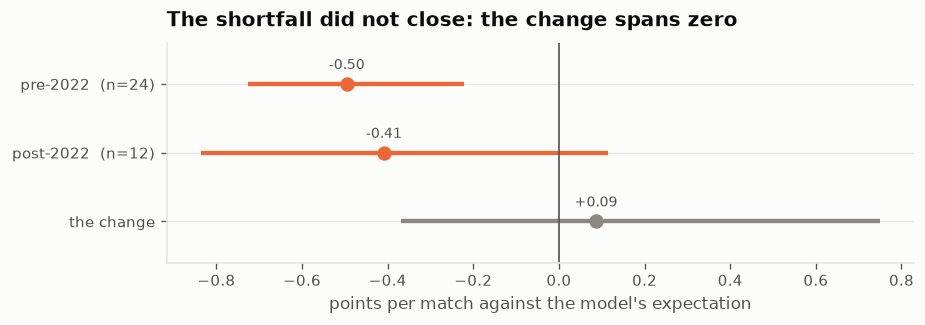

In [22]:
# The interpretable version: the points shortfall, by era.
L["era"] = L.match_id.map(mt.set_index("match_id").era)
L["blk"] = L.match_id.map(mt.set_index("match_id").blk)
L["expected_pts"] = sim
L["short"] = L.pts - L.expected_pts
LB = {e: [d.match_id.tolist() for _, d in L[L.era == e].groupby("blk")]
      for e in ("pre", "post")}
lm = L.set_index("match_id")
d_obs = L[L.era == "post"].short.mean() - L[L.era == "pre"].short.mean()
dr = []
for _ in range(4000):
    s = {e: [m for i in rng.integers(0, len(LB[e]), len(LB[e])) for m in LB[e][i]]
         for e in ("pre", "post")}
    v = lm.loc[s["post"]].short.mean() - lm.loc[s["pre"]].short.mean()
    if np.isfinite(v):
        dr.append(v)
lo, hi = np.percentile(dr, [2.5, 97.5])
rows = []
for e in ("pre", "post"):
    d = L[L.era == e]
    bb = [d.short.values[p].mean()
          for p in (rng.integers(0, len(d), len(d)) for _ in range(5000))]
    l2, h2 = np.percentile(bb, [2.5, 97.5])
    rows.append({"row": f"{e}-2022  (n={len(d)})", "est": d.short.mean(),
                 "lo": l2, "hi": h2, "kind": "level"})
rows.append({"row": "the change", "est": d_obs, "lo": lo, "hi": hi, "kind": "change"})
short_era = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7.6, 2.6))
d = short_era.iloc[::-1].reset_index(drop=True)
y = np.arange(len(d))
for i, r in d.iterrows():
    col = viz.INK_MUTED if r.kind == "change" else viz.ORANGE
    ax.hlines(i, r.lo, r.hi, color=col, lw=2.6)
    ax.scatter([r.est], [i], color=col, s=58, zorder=3)
    ax.annotate(f"{r.est:+.2f}", (r.est, i), xytext=(0, 9), ha="center",
                textcoords="offset points", fontsize=8.5, color=viz.INK_2)
ax.axvline(0, color=viz.INK_2, lw=1.0)
ax.set_yticks(y)
ax.set_yticklabels(d.row)
ax.set_ylim(-0.6, len(d) - 0.4)
ax.set_xlabel("points per match against the model's expectation")
ax.set_title("The shortfall did not close: the change spans zero")
viz.despine(ax)
plt.show()

In [23]:
# How often does Jordan even arrive at the 75th minute in each state?
at75 = []
for mid, (tl, _s, _x) in TL.items():
    d75 = sum(d for m, d in tl if m <= 75)
    at75.append({"era": info.loc[mid, "era"],
                 "at75": "leading" if d75 > 0 else ("trailing" if d75 < 0 else "level")})
at75 = pd.DataFrame(at75)   # drawn by the next cell

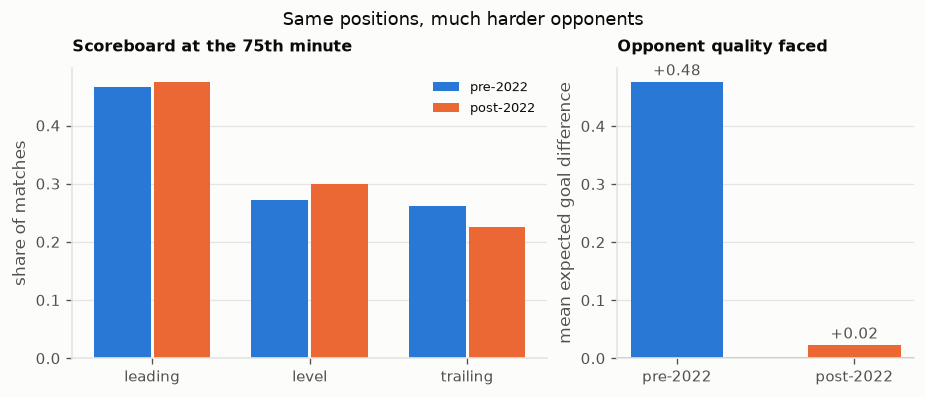

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(7.6, 3.2),
                         gridspec_kw={"width_ratios": [1.6, 1]})
a = axes[0]
sh75 = (pd.crosstab(at75.era, at75.at75, normalize="index")
        .reindex(index=["pre", "post"])[["leading", "level", "trailing"]])
x = np.arange(3)
a.bar(x - 0.19, sh75.loc["pre"], width=0.36, color=viz.BLUE, label="pre-2022")
a.bar(x + 0.19, sh75.loc["post"], width=0.36, color=viz.ORANGE, label="post-2022")
a.set_xticks(x)
a.set_xticklabels(sh75.columns)
a.set_ylabel("share of matches")
a.set_title("Scoreboard at the 75th minute", fontsize=9.5)
a.legend(fontsize=8)
viz.despine(a)

b = axes[1]
opp = mt.groupby("era").expected_gd.mean().reindex(["pre", "post"])
b.bar([0, 1], opp.values, width=0.52, color=[viz.BLUE, viz.ORANGE])
for i, v in enumerate(opp.values):
    b.annotate(f"{v:+.2f}", (i, v), xytext=(0, 4), textcoords="offset points",
               ha="center", fontsize=9, color=viz.INK_2)
b.axhline(0, color=viz.INK_2, lw=1.0)
b.set_xticks([0, 1])
b.set_xticklabels(["pre-2022", "post-2022"])
b.set_ylabel("mean expected goal difference")
b.set_title("Opponent quality faced", fontsize=9.5)
viz.despine(b)

fig.suptitle("Same positions, much harder opponents", fontsize=11)
plt.show()

**This is the part that did not improve.**

The shortfall is **−0.50** pre and **−0.41** post, a change of **+0.09, 95%
[−0.36, +0.77]**. The raw conceding rate in that cell rises 3.04 → 7.32 per 90,
alarming until the interval: [−0.08, +11.59]. Ten goals in 123 minutes
distinguishes nothing.

**The scoreboard distribution barely moves either** — Jordan reaches the 75th
minute leading in **47%** of matches in both eras.

**That is the interesting part.** Over the same period the opposition got much
harder: mean expected goal difference **+0.48 → +0.02**, and among matches
reaching 75' level, **+0.50 → −0.41**. Holding the same positions against that
much better opposition *is* the improvement — notebook 01's headline in another
register. The conversion from them did not improve at all.

So this section contributes a negative, and a useful one: **none of the
improvement came from managing tight matches better.** What the failure *is*
cannot be settled here — that needs shot locations or possession, and neither
exists for these matches.

## 6. What it isn't

Built, and returned nothing. Reported because a null with an interval is a
result, and because each one closes off an explanation that would otherwise stay
live.

In [25]:
ms["blk"] = ms.date.dt.year * 2 + (ms.date.dt.month > 6)
ms["margin"] = ms.gf - ms.ga     # before the blocks are cut, or the draws lack it
SB = {e: [d for _, d in ms[ms.era == e].groupby("blk")] for e in ("pre", "post")}

def sboot(fn, nb=1200):
    obs = fn(ms[ms.era == "post"]) - fn(ms[ms.era == "pre"])
    vals = []
    for _ in range(nb):
        s = {e: pd.concat([SB[e][i] for i in rng.integers(0, len(SB[e]), len(SB[e]))])
             for e in ("pre", "post")}
        v = fn(s["post"]) - fn(s["pre"])
        if np.isfinite(v):
            vals.append(v)
    lo, hi = np.percentile(vals, [2.5, 97.5])
    return obs, lo, hi

NULLS = [
    ("share of time leading", lambda d: (d.min_leading / d.match_end).mean()),
    ("share of time trailing", lambda d: (d.min_trailing / d.match_end).mean()),
    ("scores first", lambda d: d.first_goal.eq("for").mean()),
    ("trailed -> avoided defeat", lambda d: d.recovered.dropna().mean()),
    ("win by 3+", lambda d: (d.margin >= 3).mean()),
    ("lose by 3+", lambda d: (d.margin <= -3).mean()),
]
rows = []
for lab, fn in NULLS:
    o, lo, hi = sboot(fn)   # collected, not just printed -- the figure below uses it
    rows.append({"measure": lab, "diff": o, "lo": lo, "hi": hi,
                 "excludes_0": bool(lo > 0 or hi < 0)})
nulls = pd.DataFrame(rows)   # drawn two cells below

In [26]:
# Scoring rate per 90 minutes ACTUALLY SPENT in each state. Both numerator and
# denominator move when a match is resampled, so the rate is what is bootstrapped.
def rate(d, st, direction="gf"):
    m = d[f"min_{st}"].sum()
    return d[f"{direction}_{st}"].sum() / m * 90 if m > 0 else np.nan

srows = []
for st in ("leading", "level", "trailing"):
    o, lo, hi = sboot(lambda d, ss=st: rate(d, ss))
    a, b = rate(ms[ms.era == "pre"], st), rate(ms[ms.era == "post"], st)
    srows.append({"measure": f"scoring rate, {st}", "diff": o, "lo": lo,
                  "hi": hi, "pre": a, "post": b})

# The comparison of interest as a single quantity: does the team push when behind?
def ratio(d):
    lv = rate(d, "level")
    return rate(d, "trailing") / lv if lv > 0 else np.nan

o, lo, hi = sboot(ratio)
srows.append({"measure": "trailing / level ratio", "diff": o, "lo": lo, "hi": hi})
state_nulls = pd.DataFrame(srows)
N_TRAIL = int(ms.gf_trailing.sum())   # the whole basis of the trailing comparison

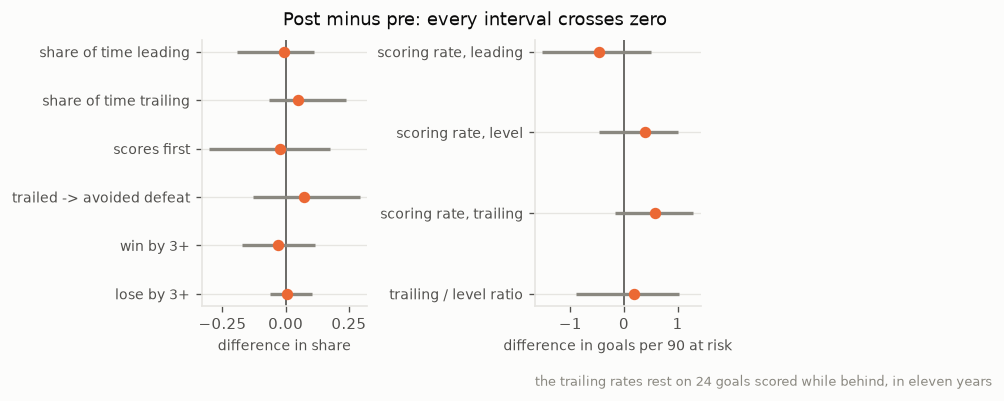

In [27]:
# Shares and goals-per-90 are not the same unit, so they do not share an axis.
fig, axes = plt.subplots(1, 2, figsize=(7.8, 3.2))
for ax, tab, unit in ((axes[0], nulls, "difference in share"),
                      (axes[1], state_nulls, "difference in goals per 90 at risk")):
    d = tab.iloc[::-1].reset_index(drop=True)
    y = np.arange(len(d))
    ax.hlines(y, d.lo, d.hi, color=viz.INK_MUTED, lw=2.0)
    ax.scatter(d["diff"], y, color=viz.ORANGE, s=34, zorder=3)
    ax.axvline(0, color=viz.INK_2, lw=1.0, zorder=0)
    ax.set_yticks(y)
    ax.set_yticklabels(d.measure, fontsize=8.5)
    ax.set_xlabel(unit, fontsize=8.5)
    viz.despine(ax)
fig.suptitle("Post minus pre: every interval crosses zero", fontsize=11)
axes[1].annotate(f"the trailing rates rest on {N_TRAIL} goals scored while behind, "
                 f"in eleven years", xy=(0, -0.30), xycoords="axes fraction",
                 fontsize=8, color=viz.INK_MUTED)
plt.show()

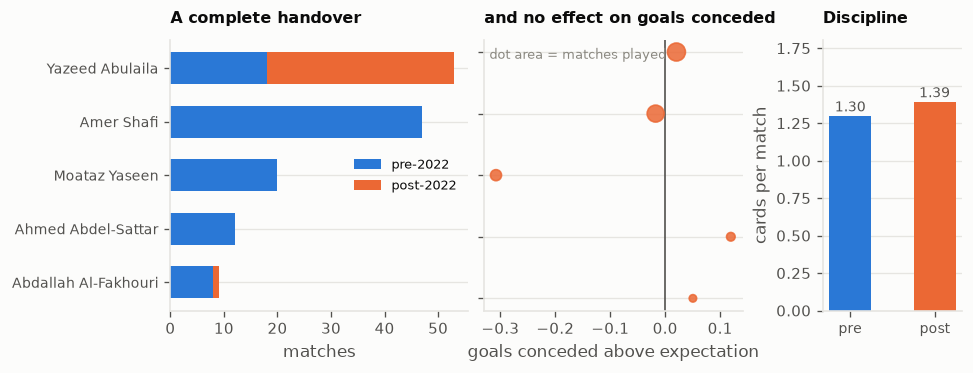

In [28]:
# The keeper: a complete handover, and no effect on goals conceded
kp = pd.read_csv(SQUAD / "keeper.csv")
kj = kp[kp.squad_id == "3e22f0fa"].merge(
    mt[["match_id", "era", "date", "ga", "expected_ga"]], on="match_id")
kj["above"] = kj.ga - kj.expected_ga
k = (kj.groupby("Player").agg(matches=("match_id", "size"),
                              pre=("era", lambda s: (s == "pre").sum()),
                              post=("era", lambda s: (s == "post").sum()),
                              first=("date", "min"), last=("date", "max"),
                              ga=("ga", "mean"), ga_above_expected=("above", "mean"))
     .sort_values("matches", ascending=False))
k["first"] = k["first"].dt.date
k["last"] = k["last"].dt.date
kk = k[k.matches >= 8].iloc[::-1]
fig, axes = plt.subplots(1, 3, figsize=(8.0, 3.0),
                         gridspec_kw={"width_ratios": [1.5, 1.3, 0.7]})
y = np.arange(len(kk))
a = axes[0]
a.barh(y, kk.pre, height=0.6, color=viz.BLUE, label="pre-2022")
a.barh(y, kk.post, left=kk.pre, height=0.6, color=viz.ORANGE, label="post-2022")
a.set_yticks(y)
a.set_yticklabels(kk.index, fontsize=8.5)
a.set_xlabel("matches")
a.set_title("A complete handover", fontsize=9.5)
a.legend(fontsize=8, loc="center right")
viz.despine(a)

b = axes[1]
# Area tracks matches played: a 20-match mean should not read as loudly as a
# 53-match one, and none of these carries an interval.
b.scatter(kk.ga_above_expected, y, color=viz.ORANGE, zorder=3,
          s=kk.matches.values * 2.2, alpha=0.85)
b.axvline(0, color=viz.INK_2, lw=1.0)
b.set_yticks(y)
b.set_yticklabels([])
b.set_xlabel("goals conceded above expectation")
b.set_title("and no effect on goals conceded", fontsize=9.5)
b.annotate("dot area = matches played", xy=(0.02, 0.97), xycoords="axes fraction",
           va="top", fontsize=7.5, color=viz.INK_MUTED)
viz.despine(b)

c = axes[2]
cards = mt.groupby("era").n_cards.mean().reindex(["pre", "post"])
c.bar([0, 1], cards.values, width=0.5, color=[viz.BLUE, viz.ORANGE])
for i, v in enumerate(cards.values):
    c.annotate(f"{v:.2f}", (i, v), xytext=(0, 3), ha="center",
               textcoords="offset points", fontsize=8.5, color=viz.INK_2)
c.set_xticks([0, 1])
c.set_xticklabels(["pre", "post"], fontsize=8.5)
c.set_ylim(0, cards.max() * 1.3)
c.set_ylabel("cards per match")
c.set_title("Discipline", fontsize=9.5)
viz.despine(c)
plt.show()

- **Match state** — time leading, trailing, scoring first, recovering. Jordan did
  not become a team that manages the scoreboard differently.
- **Scoring rate by state.** The point estimates are seductive: pre-2022 Jordan
  looks like a front-runner, scoring *below its own level-state rate* when
  chasing — the opposite of Lago-Peñas & Gómez-López (2014). But it rests on **24
  goals scored while trailing in eleven years**, and the interval cannot carry it.
- **Margins** — heavy wins and defeats at the old rates. What changed is that
  matches got higher-scoring overall.
- **The goalkeeper.** The position does change hands — Shafi 47 matches and none
  after Feb 2021, Abulaila takes over — and goals conceded above expectation are
  identical. A plausible mechanism, measured and ruled out.
- **Discipline** — cards per match, unchanged.

Excluded rather than tested: **substitutions**, confounded by the 2020 five-sub
rule two years before the cut; **manager**, 15 spells and inseparable from squad
change at this n.

## Summary

| | | |
|---|---|---|
| **Supported** | a narrower group of scorers | outside the rarefied pre-2022 range on distinct scorers, top-3 share and HHI |
| | a more settled team | minutes top-11 **+0.247** [+0.135, +0.351]; familiarity **+0.217** [+0.113, +0.337] |
| | more goals from midfield | **+0.148** [+0.039, +0.315] — but it cannot locate a date (section 0) |
| **Unchanged** | late conceding | a third of goals against in the last fifteen minutes, both eras |
| | level scorelines | shortfall −0.50 pre, −0.41 post; change **+0.09** [−0.36, +0.77] |
| **Not established** | dependence on one player | top-1 share sits *inside* the rarefied range |
| | game management, keeper, discipline, margins | every interval spans zero |

### So how did the results get better?

**Through the attack, from a narrower group, with a more settled team.** More of
the goals from a small set of players and from midfield, minutes concentrated in
fewer men, those men having played together more. Against opposition that got
substantially harder — expected goal difference **+0.48 → +0.02** — that produced
better results.

**Not through game management.** Same scoreboard positions at the 75th minute,
converted exactly as badly. Not through the goalkeeper or discipline either. The
list of things that *didn't* change is what stops "Jordan got better" from being
a story you can tell any way you like.

### What this licenses

A **coincidence with uncertainty**, and no more. Squad change, coaching change
and scheduling all move together across mid-2022, ~40 matches follow it, and no
design here separates them. The one thing worth adding beyond the association is
a caution: a rise carried by a narrow group is more fragile than one carried by a
broad one, and **top-3 share is the number to watch** if the level slips.

## What we can still improve

Ranked by how much each would change what is above. The first corrects a claim
already made; the rest are things this notebook does not know.

### 1. Section 5's shortfall is partly the model's fault

Its expectation comes from simulating the last fifteen minutes at each fixture's
own model goal rates — at a **constant rate whatever the scoreboard says**. The
match-status literature says that is wrong here specifically: late goals are more
common when a match is level, everywhere, for everyone. Two diagnostics on the
same 36 matches:

In [29]:
# Does the constant-rate model fit the last fifteen minutes of a level match?
late = pd.DataFrame([{"match_id": m,
                      "gf75": sum(1 for x, d in TL[m][0] if x > 75 and d > 0),
                      "ga75": sum(1 for x, d in TL[m][0] if x > 75 and d < 0)}
                     for m in L.match_id]).merge(L, on="match_id")
sg, sd = [], []
for r in late.itertuples():
    kf = rng.poisson(r.expected_gf * 15 / 90, 40000)
    ka = rng.poisson(r.expected_ga * 15 / 90, 40000)
    sg.append((kf + ka).mean())
    sd.append((kf == ka).mean())
# both halves of this comparison are drawn two cells below

In [30]:
# DIRECTION is the part no general effect explains. "Level matches produce more
# late goals" predicts volume. It does not predict them going one way.
f, g = int(late.gf75.sum()), int(late.ga75.sum())
sh = []
for _ in range(20000):
    d = late.sample(len(late), replace=True, random_state=int(rng.integers(1e9)))
    t = d.gf75.sum() + d.ga75.sum()
    if t:
        sh.append(d.gf75.sum() / t)
sh_lo, sh_hi = np.percentile(sh, [2.5, 97.5])
mdl = (late.expected_gf / (late.expected_gf + late.expected_ga)).mean()
# drawn by the next cell

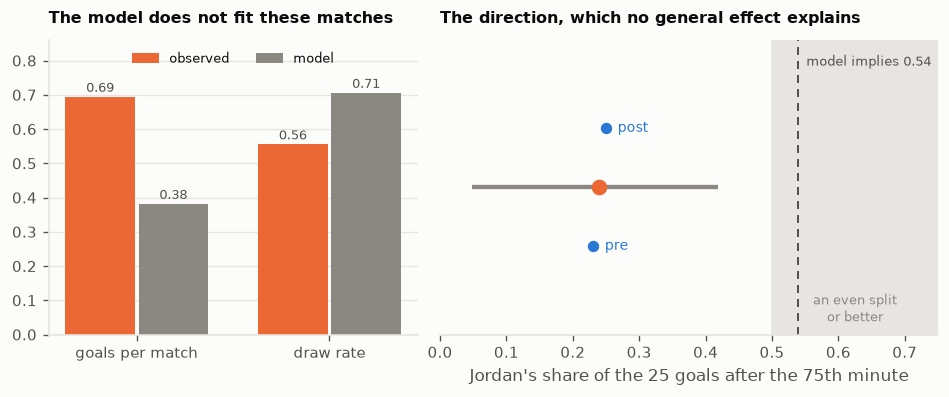

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(7.8, 3.2),
                         gridspec_kw={"width_ratios": [1, 1.35]})
a = axes[0]
x = np.arange(2)
obs_v = [(late.gf75 + late.ga75).mean(), (late.pts == 1).mean()]
mod_v = [np.mean(sg), np.mean(sd)]
for off, vals, col, lab in ((-0.19, obs_v, viz.ORANGE, "observed"),
                            (0.19, mod_v, viz.INK_MUTED, "model")):
    a.bar(x + off, vals, width=0.36, color=col, label=lab)
    for xi, v in zip(x + off, vals):
        a.annotate(f"{v:.2f}", (xi, v), xytext=(0, 3),
                   textcoords="offset points", ha="center", fontsize=8,
                   color=viz.INK_2)
a.set_xticks(x)
# two different units, side by side on purpose -- say so rather than hide it
a.set_xticklabels(["goals per match", "draw rate"])
a.set_ylim(0, max(obs_v + mod_v) * 1.22)
a.set_title("The model does not fit these matches", fontsize=9.5)
a.legend(fontsize=8, loc="upper center", ncol=2)
viz.despine(a)

b = axes[1]
b.axvspan(0.5, 0.75, color=viz.GRID, zorder=0)
b.annotate("an even split\nor better", xy=(0.625, 0.03),
           xycoords=("data", "axes fraction"), ha="center", va="bottom",
           fontsize=8, color=viz.INK_MUTED)
b.hlines(0, sh_lo, sh_hi, color=viz.INK_MUTED, lw=2.6)
b.scatter([f / (f + g)], [0], color=viz.ORANGE, s=70, zorder=4)
for k, (e, yy) in enumerate((("pre", -0.8), ("post", 0.8))):
    dd = late[late.era == e]
    b.scatter([dd.gf75.sum() / (dd.gf75.sum() + dd.ga75.sum())], [yy],
              color=viz.BLUE, s=34, zorder=4)
    b.annotate(e, (dd.gf75.sum() / (dd.gf75.sum() + dd.ga75.sum()), yy),
               xytext=(7, 0), textcoords="offset points", fontsize=8.5,
               color=viz.BLUE, va="center")
b.axvline(mdl, color=viz.INK_2, lw=1.2, ls=(0, (4, 3)))
b.annotate(f"model implies {mdl:.2f}", (mdl, 1.0),
           xycoords=("data", "axes fraction"), xytext=(5, -9),
           textcoords="offset points", fontsize=8, color=viz.INK_2, va="top")
b.set_ylim(-2, 2)
b.set_yticks([])
b.set_xlim(0, 0.75)
b.set_xlabel(f"Jordan's share of the {f + g} goals after the 75th minute")
b.set_title("The direction, which no general effect explains", fontsize=9.5)
viz.despine(b, keep=("bottom",))
plt.show()

**Re-centre section 5 on direction, not volume.** A busy last fifteen minutes in
a level match is ordinary football. Those goals going one way **three times in
four**, in fixtures the model makes Jordan the favourite in, is not — and it
holds in both eras. Keep the rate ratio and the points shortfall as symptoms
beneath it, never as clean comparisons.

### 2. There is no placebo here

The plan calls for the same pipeline on three or four comparable AFC nations;
notebook 01 does it for strength, this notebook does nothing. Every measure is
Jordan against its own past, so anything really about international football in
the 2020s — squads settling, scoring narrowing, late goals rising — would look
identical. **The largest hole**, and section 0 cannot fill it: that check moves
the date, not the team.

Cost: ~600 match reports, mostly uncached. A cheap partial version would take
only the level-at-75 finding, which needs goal minutes and nothing else.

### 3. Three planned squad measures were never built

XI age, debuts per window, squad turnover (Jaccard). The data is already on disk.
Debuts look like they would say something — **13 in 2021, then 1 and 1** — but
those years hold 21, 6 and 5 covered matches, so per match it is 0.62 → 0.17 →
0.20. Smaller than the counts suggest, and exactly why it needs building with an
interval rather than quoting.

### 4. The mechanism is out of reach, and will stay there

The obvious reading of section 5 — chasing a winner, caught on the break — needs
shot locations or possession. Possession exists for 27 matches, concentrated
after 2023, so filling it in would put the coverage boundary on the treatment
date. It stays a description, not an explanation.

### 5. Nineteen matches have no event feed

14 friendlies, 5 competitive: FBref reports with no timeline, so they reach the
squad measures but nothing in sections 4-6. Coverage is balanced across eras at
89%, so noise rather than bias — but it caps the post side near 40 matches, which
is why the state-crossed intervals are as wide as they are.

### 6. Smaller, recorded so they are not rediscovered

- **Minutes at risk stop at 90** while stoppage is always played. Section 5
  survives eight added minutes; the clock is still wrong.
- **Managers have no stable id** — name-keyed, and checked by hand.
- **Six Arab Cup names** are unconfirmed transliteration matches, deliberately
  unmerged. Confirming them adds ten matches.
- **Notebooks 01 and 02 predate the manager fix**; notebook 02's
  column-completeness figure is stale.

## Appendix — one measure this notebook deliberately does not use

`match_table` carries `gf_above_expected` — goals minus the model's expectation
for that fixture. Tempting as an outcome, and wrong for this question.

The model refits every six months on data *before* each match, so the residual
measures how far Jordan beat its **contemporaneous forecast**, not how much it
improved. Jordan's attack rising and its opponents strengthening cancel in the
expectation: expected goals-for is flat across the boundary while actual rises. A
team improving faster than a 730-day half-life can track shows a positive
residual for that reason alone.

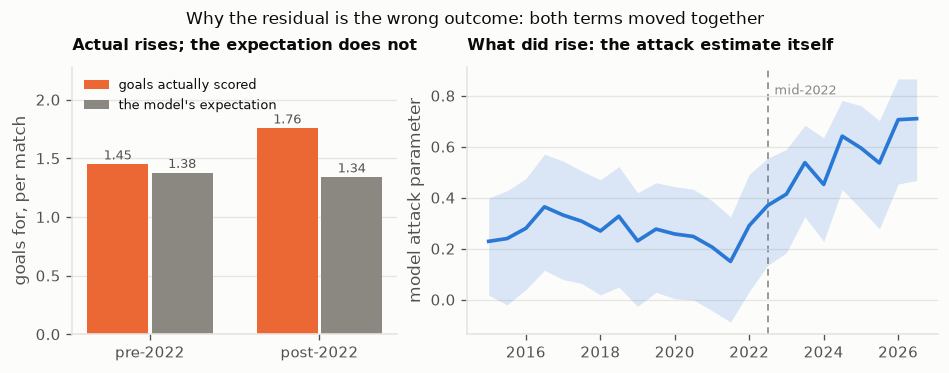

In [32]:
tr = pd.read_csv(ROOT / "outputs" / "jordan_strength_ci.csv", parse_dates=["date"])
g = mt.groupby("era")[["gf", "expected_gf"]].mean().reindex(["pre", "post"])

fig, axes = plt.subplots(1, 2, figsize=(7.8, 3.0),
                         gridspec_kw={"width_ratios": [1, 1.45]})
a = axes[0]
x = np.arange(2)
a.bar(x - 0.19, g.gf.values, width=0.36, color=viz.ORANGE, label="goals actually scored")
a.bar(x + 0.19, g.expected_gf.values, width=0.36, color=viz.INK_MUTED,
      label="the model's expectation")
for off, vals in ((-0.19, g.gf.values), (0.19, g.expected_gf.values)):
    for xi, v in zip(x + off, vals):
        a.annotate(f"{v:.2f}", (xi, v), xytext=(0, 3), ha="center",
                   textcoords="offset points", fontsize=8, color=viz.INK_2)
a.set_xticks(x)
a.set_xticklabels(["pre-2022", "post-2022"])
a.set_ylim(0, max(g.gf.max(), g.expected_gf.max()) * 1.3)
a.set_ylabel("goals for, per match")
a.set_title("Actual rises; the expectation does not", fontsize=9.5)
a.legend(fontsize=7.5, loc="upper left")
viz.despine(a)

b = axes[1]
trw = tr[tr.date >= START]
b.fill_between(trw.date, trw.attack_lo, trw.attack_hi, color=viz.BLUE,
               alpha=0.16, lw=0)
b.plot(trw.date, trw.attack, color=viz.BLUE, lw=2.2)
viz.mark_split(b)
b.set_ylabel("model attack parameter")
b.set_title("What did rise: the attack estimate itself", fontsize=9.5)
viz.despine(b)
fig.suptitle("Why the residual is the wrong outcome: both terms moved together",
             fontsize=10)
plt.show()

Hence **shares and counts** throughout sections 1-3: they need no expectation, so
nothing there depends on the model being calibrated. Sections 4 and 5 do use it,
to adjust for opponent quality, and that is where its limits start to bite — the
first item in **What we can still improve**.